베르누이는 이진데이터에 적용(대부분 텍스트 데이터 분류할때 활용)<br/>

속성이 아주 많지만 대부분의 속성이 0/1 과 같은 이산적인 특징이 있을때 훈련데이터가 많지 않아도 좋은 성능을 발휘한다.

In [1]:
from sklearn.datasets import load_digits

# 1. 데이터 불러오기
digits = load_digits()
print(digits.keys())
print(f'feature_names : {digits.feature_names}')
print(f'target_names : {digits.target_names}')

dict_keys(['data', 'target', 'frame', 'feature_names', 'target_names', 'images', 'DESCR'])
feature_names : ['pixel_0_0', 'pixel_0_1', 'pixel_0_2', 'pixel_0_3', 'pixel_0_4', 'pixel_0_5', 'pixel_0_6', 'pixel_0_7', 'pixel_1_0', 'pixel_1_1', 'pixel_1_2', 'pixel_1_3', 'pixel_1_4', 'pixel_1_5', 'pixel_1_6', 'pixel_1_7', 'pixel_2_0', 'pixel_2_1', 'pixel_2_2', 'pixel_2_3', 'pixel_2_4', 'pixel_2_5', 'pixel_2_6', 'pixel_2_7', 'pixel_3_0', 'pixel_3_1', 'pixel_3_2', 'pixel_3_3', 'pixel_3_4', 'pixel_3_5', 'pixel_3_6', 'pixel_3_7', 'pixel_4_0', 'pixel_4_1', 'pixel_4_2', 'pixel_4_3', 'pixel_4_4', 'pixel_4_5', 'pixel_4_6', 'pixel_4_7', 'pixel_5_0', 'pixel_5_1', 'pixel_5_2', 'pixel_5_3', 'pixel_5_4', 'pixel_5_5', 'pixel_5_6', 'pixel_5_7', 'pixel_6_0', 'pixel_6_1', 'pixel_6_2', 'pixel_6_3', 'pixel_6_4', 'pixel_6_5', 'pixel_6_6', 'pixel_6_7', 'pixel_7_0', 'pixel_7_1', 'pixel_7_2', 'pixel_7_3', 'pixel_7_4', 'pixel_7_5', 'pixel_7_6', 'pixel_7_7']
target_names : [0 1 2 3 4 5 6 7 8 9]


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import BernoulliNB
# 2. 데이터 분리

x_train, x_test, y_train, y_test = train_test_split(digits.data, digits.target, stratify=digits.target, random_state=42)

# 3. 학습
bn = BernoulliNB(alpha=0.1).fit(x_train, y_train)

# 4. 테스트
print(f'train score : {bn.score(x_train, y_train):.2f}')
print(f'test score : {bn.score(x_test, y_test):.2f}')

train score : 0.87
test score : 0.85


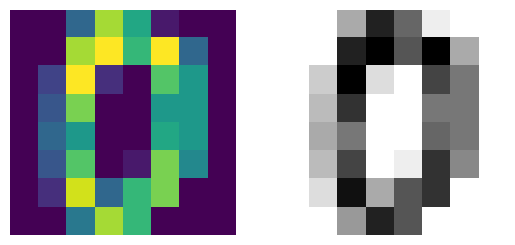

In [3]:
import matplotlib.pyplot as plt

# 5. 원리를 알아보자
data = digits.data
#print(data[0,:]) # 0 층에 있는 모든 호 -> 0번째의 모든값(특정 손글씨 데이터)
#print(len(data[0,:])) # 64 -> 8X8
plt.subplot(121)
plt.imshow(data[0,:].reshape(8,8))
plt.axis('off')
plt.subplot(122)
plt.imshow(data[0,:].reshape(8,8), cmap=plt.cm.binary)
plt.axis('off')
plt.show()

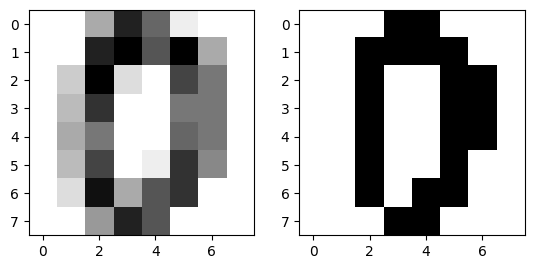

train score : 0.91
test score : 0.89


In [9]:
from sklearn.preprocessing import Binarizer

#  정확도를 올리기 위해서는 이진데이터 형태로 변경해 주는것이 좋다.
# threadhold = 강도
# threshold=7 -> 7보다 크면 1 아니면 0
x = Binarizer(threshold=7).fit_transform(digits.data)
y = digits.target

# 어떻게 변했을까?
plt.subplot(121)
plt.imshow(digits.data[0,:].reshape(8,8),cmap=plt.cm.binary)
plt.subplot(122)
plt.imshow(x[0,:].reshape(8,8),cmap=plt.cm.binary)
plt.show()

x_train, x_test, y_train, y_test = train_test_split(x, y, stratify=digits.target, random_state=42)

# 3. 학습
bn = BernoulliNB(alpha=0.1).fit(x_train, y_train)

# 4. 테스트
print(f'train score : {bn.score(x_train, y_train):.2f}')
print(f'test score : {bn.score(x_test, y_test):.2f}')